Harry Ferguson - CIS 361 - Summer 2026 - Final Project

1. Exploratory Data Analysis

In [1]:
# All the necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import emoji
from spellchecker import SpellChecker
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import spacy
import scipy.sparse as sp
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import defaultdict
from transformers import BertTokenizer, BertForSequenceClassification
import torch
from torch.optim import AdamW

C:\Users\hsfer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Read in the file
df = pd.read_csv('Flipkart_Reviews - Electronics.csv')
# Select the records for the product
product_df = df[df['product_title'] == 'BoAt Rockerz 235v2 with ASAP charging Version 5.0 Bluetooth Headset']
# Show examples of typical record
print(product_df.head())
print('\nTotal number of records:',len(product_df))

         product_id                                      product_title  \
0  ACCFZGAQJGYCYDCM  BoAt Rockerz 235v2 with ASAP charging Version ...   
1  ACCFZGAQJGYCYDCM  BoAt Rockerz 235v2 with ASAP charging Version ...   
2  ACCFZGAQJGYCYDCM  BoAt Rockerz 235v2 with ASAP charging Version ...   
3  ACCFZGAQJGYCYDCM  BoAt Rockerz 235v2 with ASAP charging Version ...   
4  ACCFZGAQJGYCYDCM  BoAt Rockerz 235v2 with ASAP charging Version ...   

   rating            summary  \
0       5  Terrific purchase   
1       5  Terrific purchase   
2       5             Super!   
3       5             Super!   
4       5  Terrific purchase   

                                              review       location  \
0  1-more flexible2-bass is very high3-sound clar...        Shirala   
1     Super sound and good looking I like that prize  Visakhapatnam   
2  Very much satisfied with the device at this pr...      Kozhikode   
3  Nice headphone, bass was very good and sound i...          Jaora   
4  Soun

In [3]:
# Is there any missing data
print(product_df[['rating', 'summary', 'review', 'date']].isna().sum(), '\n')
# Count of each rating (1 - 5)
print(product_df['rating'].value_counts())

rating     0
summary    0
review     0
date       0
dtype: int64 

rating
5    1045
4     397
1     270
3     146
2      63
Name: count, dtype: int64


2. Text Preprocessing and Cleaning for MultinomialNB model

In [4]:
product_df['product_review'] = product_df['summary'] + ' ' + product_df['review'] # The Summary field is the "title" of the review
product_df['label'] = np.select([product_df['rating'] > 3, product_df['rating'] == 3], [1, 0], default=-1) # Positive is 4-5, neutral is 3, negative is 1-2
reviews_df = product_df[['product_review', 'label', 'date']]
print(reviews_df.head())
print('\nTotal number of reviews: ', len(reviews_df), '\n')
reviews_df['label'].value_counts()
reviews_copy_df = reviews_df.copy() # For use by the BERT transformer

                                      product_review  label          date
0  Terrific purchase 1-more flexible2-bass is ver...      1  8 months ago
1  Terrific purchase Super sound and good looking...      1  8 months ago
2  Super! Very much satisfied with the device at ...      1     Feb, 2020
3  Super! Nice headphone, bass was very good and ...      1  7 months ago
4  Terrific purchase Sound quality super battery ...      1  8 months ago

Total number of reviews:  1921 



In [5]:
print('Number of product reviews with emojis and special characters before emoji cleaning:', len(reviews_df[reviews_df['product_review'].str.contains(r'[\u263a-\U0001f645]')]))
reviews_df['product_review'] = reviews_df['product_review'].apply(lambda review: emoji.demojize(review)) # Convert emoji to text so text can be considered by model
print('Number of product reviews with emojis and special characters after emoji cleaning:', len(reviews_df[reviews_df['product_review'].str.contains(r'[\u263a-\U0001f645]')]))
pd.set_option("display.max_colwidth", None)
print(reviews_df[reviews_df['product_review'].str.contains(r'[\u263a-\U0001f645]')]) # These reviews contain checkmarks

Number of product reviews with emojis and special characters before emoji cleaning: 176
Number of product reviews with emojis and special characters after emoji cleaning: 2
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              product_review  \
20    Does the job Hi Seekers, I am writing this review after 2 weeks of daily use, lets start with pros and cons Pros-✓Sounds Quality is good✓ Bass is good enough✓ Look is okay as per this price range ✓ All essential controls are provided✓ Backup is decentConsxx Bluetooth range is too short (even if you are walki

In [6]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hsfer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hsfer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hsfer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hsfer\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [7]:
speller = SpellChecker()
lemmatizer = spacy.load('en_core_web_sm')

def prepare_text(review):
    review = review.lower().strip()
    tokens = word_tokenize(review)
    tokens = [word for word in tokens if word.isalnum() and word not in stopwords.words('english')] # Remove punctuation and stop words
    tokens = [speller.correction(word) or word for word in tokens] # Correct misspellings
    cleaned_text = ' '.join(tokens)
    # Lemmanize text
    lemma_text = lemmatizer(cleaned_text)
    lemmas = [token.lemma_ for token in lemma_text]
    return ' '.join(lemmas) 

reviews_df['product_review'] = reviews_df['product_review'].apply(lambda review: prepare_text(review))
    
print(reviews_df[reviews_df['product_review'].str.contains(r'[\u263a-\U0001f645]')]) # Confirm checkmarks removed 
reviews_df['product_review'].head(20)

Empty DataFrame
Columns: [product_review, label, date]
Index: []


0                                                                                    terrific purchase clarity good back 6 8 hour thing fast charge system available 20 min charge get long 4 hour back look awesome gaming product support 100 want gaming recommend please buy want music product well wireless headphone compare headphone price
1                                                                                                                                                                                                                                                                                                terrific purchase super sound good look like prize
2                                                                                                                                     super much satisfied device price point awesome brand design wise like rocker 255 model blindly first day zero review wonderful choice must enable we connect device simultaneously vibrat

3. MultinomialNB Model Training and Results


10-fold Cross Validation:
[0.9015544  0.890625   0.91145833 0.91666667 0.89583333 0.90104167
 0.890625   0.90104167 0.875      0.90104167]

Accuracy: 0.9298701298701298

Classification Report:
              precision    recall  f1-score   support

    Negative       0.99      0.93      0.96        72
     Neutral       0.55      0.89      0.68        27
    Positive       0.98      0.93      0.96       286

    accuracy                           0.93       385
   macro avg       0.84      0.92      0.86       385
weighted avg       0.95      0.93      0.94       385



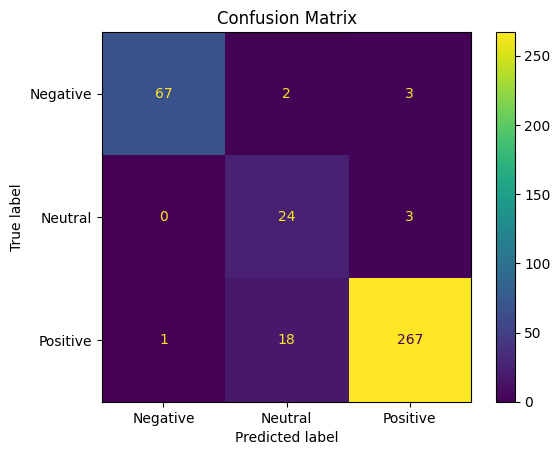

In [ ]:
reviews_df = reviews_df.sample(frac=1).reset_index(drop=True) # shuffle the dataframes
reviews = list(reviews_df[['product_review', 'label']].to_records(index=False))
train_reviews, test_reviews = train_test_split(reviews, test_size=0.2, random_state=13)

X_train, y_train = zip(*train_reviews)
X_test, y_test = zip(*test_reviews)

vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

clf = MultinomialNB()
sample_weight = compute_sample_weight('balanced', y_train) # To handle unbalanced datatset
clf.fit(X_train_tfidf, y_train, sample_weight=sample_weight)

y_pred = clf.predict(X_test_tfidf)

print('\n10-fold Cross Validation:')
X = sp.vstack((X_train_tfidf, X_test_tfidf))
y = np.concatenate((y_train, y_test))
print(cross_val_score(clf, X, y, cv=10))

def show_results(y_test, y_pred):
    accuracy = accuracy_score(y_test, y_pred)
    print("\nAccuracy:", accuracy)

    labels = ('Negative', 'Neutral', 'Positive')

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0, target_names=labels))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot()
    plt.title('Confusion Matrix')
    plt.show()

show_results(y_test, y_pred)

4. MultinomialNB Model Prediction


Accuracy: 0.5353535353535354

Classification Report:
              precision    recall  f1-score   support

    Negative       0.54      0.45      0.49        33
     Neutral       0.41      0.48      0.44        33
    Positive       0.69      0.67      0.68        33

    accuracy                           0.54        99
   macro avg       0.54      0.54      0.54        99
weighted avg       0.54      0.54      0.54        99



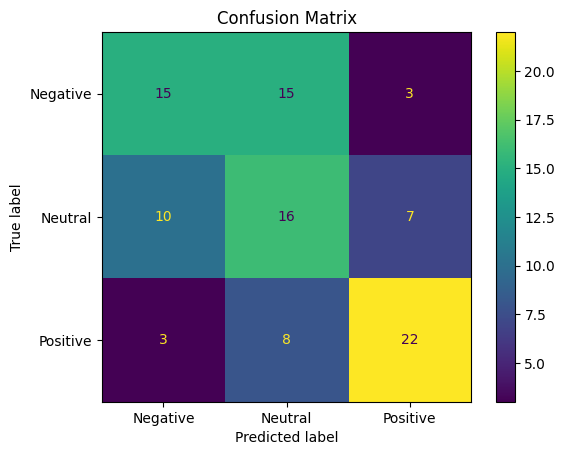

In [9]:
predict_df = pd.read_csv('boat_rockerz_235v2_reviews.csv') # File of 99 sentiments (33 of each class) generated by ChatGPT
predict_reviews = predict_df['Review'].apply(lambda review: prepare_text(review)).tolist()
predict_sentiment = predict_df['Sentiment'].map({'Positive': 1, 'Neutral': 0, 'Negative': -1}).tolist()

predictions = []
for review in predict_reviews:
    predictions.append(clf.predict(vectorizer.transform([review]))[0])

show_results(predict_sentiment, predictions)

5. Word Clouds

In [10]:
# Count of each date (to determine how to filter reviews for today and for this year).
print(product_df['date'].value_counts())

date
8 months ago     644
1 month ago      286
7 months ago     281
Today            198
4 months ago     129
Feb, 2020         73
2 months ago      68
6 months ago      62
9 months ago      52
Mar, 2020         41
3 months ago      23
5 months ago      10
6 days ago         8
9 days ago         8
27 days ago        6
10 months ago      4
11 months ago      3
23 days ago        2
5 days ago         2
11 days ago        2
13 days ago        2
14 days ago        2
19 days ago        2
20 days ago        2
22 days ago        2
24 days ago        2
25 days ago        2
26 days ago        2
1 day ago          1
2 days ago         1
4 days ago         1
Name: count, dtype: int64


Current Review Sentiments: label
Positive    0.777778
Neutral     0.131313
Negative    0.090909
Name: proportion, dtype: float64
12-Month Review Sentiments: label
Positive    0.745434
Negative    0.175429
Neutral     0.079137
Name: proportion, dtype: float64


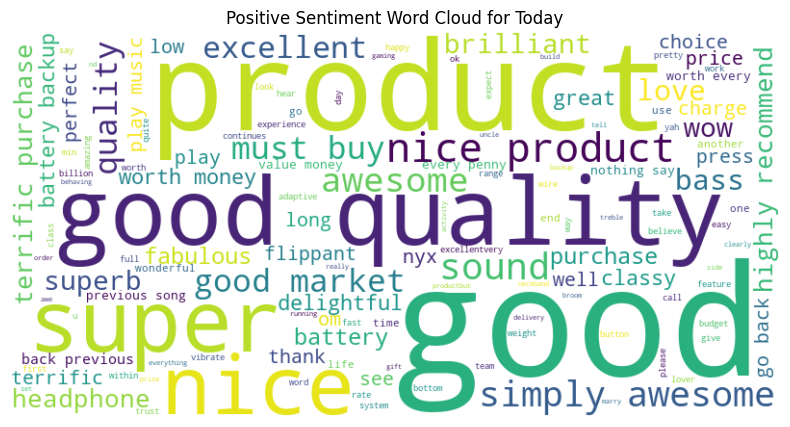

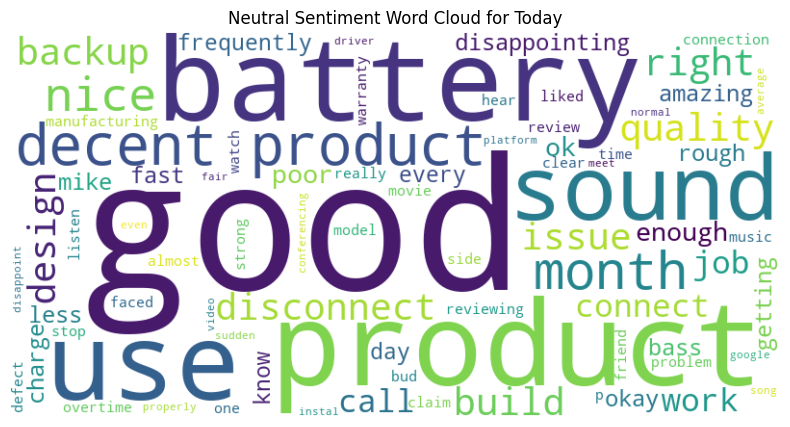

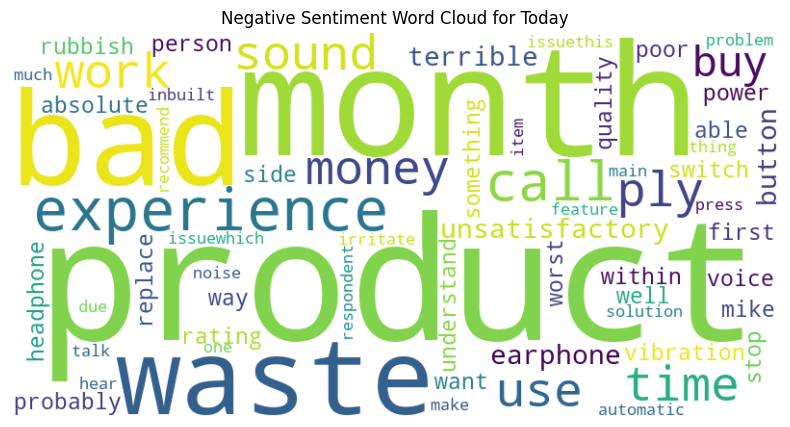

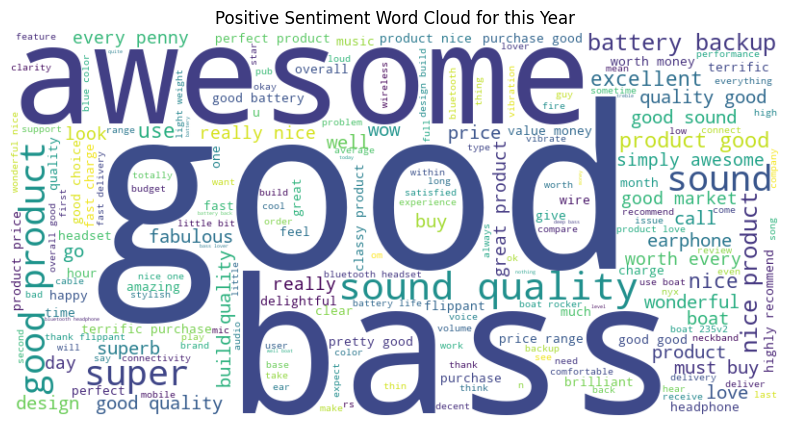

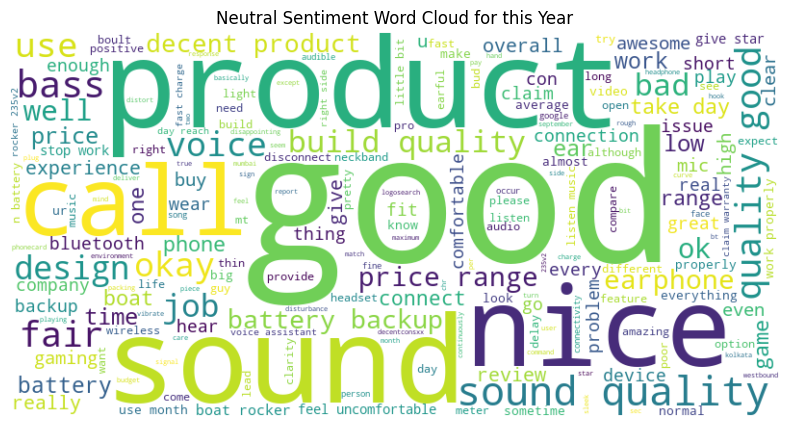

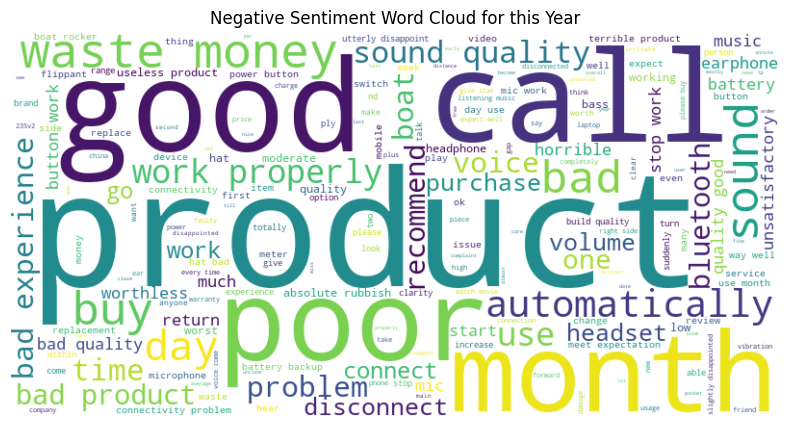

In [19]:
labels = { -1: 'Negative', 0: 'Neutral', 1: 'Positive'}

def make_word_cloud(filtered_df, dd):
    sentiment_words = defaultdict(str)
    for row in filtered_df[['product_review', 'label']].itertuples():
        words = row.product_review.split()
        sentiment_words[labels[row.label]] += " ".join(words) + " "
        
    for sentiment, words in sorted(sentiment_words.items(), reverse=True):
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(words)
        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.title(sentiment.capitalize() + " Sentiment Word Cloud for " + dd)
        plt.axis('off')
        plt.show()

today_reviews_df = reviews_df[reviews_df['date'] == 'Today'] # Current reviews
year_reviews_df = reviews_df[~reviews_df['date'].str.contains('2020')] # Reviews for the last 12 months
print('Current Review Sentiments:', today_reviews_df['label'].value_counts(normalize=True).rename(labels))
print('12-Month Review Sentiments:', year_reviews_df['label'].value_counts(normalize=True).rename(labels))
make_word_cloud(today_reviews_df, 'Today')
make_word_cloud(year_reviews_df, 'this Year')

6. BERT Transformer Training and Results

In [12]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=3)

def make_tensors(reviews_df):
    text = reviews_df['product_review'].tolist()
    encoded_dict = tokenizer(text, return_tensors="pt", padding='longest', truncation=True)
    labels = torch.tensor(reviews_df['label'].values)
    return encoded_dict.input_ids, encoded_dict.attention_mask, labels

reviews_copy_df['label'] += 1
train_reviews, test_reviews = train_test_split(reviews_copy_df, test_size=0.2, random_state=99)

train_input_ids, train_attention_masks, train_labels = make_tensors(train_reviews)
test_input_ids, test_attention_masks, test_labels = make_tensors(test_reviews)

# Convert to PyTorch DataLoader
BATCH_SIZE = 32
train_data = torch.utils.data.TensorDataset(train_input_ids, train_attention_masks, train_labels)
train_sampler = torch.utils.data.RandomSampler(train_data)
train_dataloader = torch.utils.data.DataLoader(train_data, sampler=train_sampler, batch_size=BATCH_SIZE)

test_data = torch.utils.data.TensorDataset(test_input_ids, test_attention_masks, test_labels)
test_sampler = torch.utils.data.SequentialSampler(test_data)
test_dataloader = torch.utils.data.DataLoader(test_data, sampler=test_sampler, batch_size=BATCH_SIZE)

# Fine-tune the BERT model
optimizer = AdamW(model.parameters(), lr=2e-5, eps=1e-8)
EPOCHS = 3

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2474.46it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

In [13]:
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for batch in train_dataloader:
        optimizer.zero_grad()
        input_ids, attention_mask, labels = batch
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()
        loss.backward()
        optimizer.step()

    avg_train_loss = total_loss / len(train_dataloader)

    print(f'Epoch {epoch + 1}/{EPOCHS}, Average Training Loss: {avg_train_loss}')

Epoch 1/3, Average Training Loss: 0.5940599742655953
Epoch 2/3, Average Training Loss: 0.20627268310636282
Epoch 3/3, Average Training Loss: 0.052359115332365036



Accuracy: 0.9896103896103896

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        63
     Neutral       1.00      0.85      0.92        26
    Positive       0.99      1.00      0.99       296

    accuracy                           0.99       385
   macro avg       1.00      0.95      0.97       385
weighted avg       0.99      0.99      0.99       385



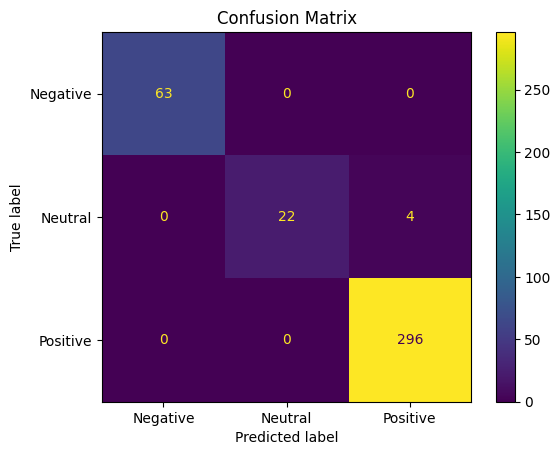

In [14]:
model.eval()
preds = []
true_labels = []

for batch in test_dataloader:
    input_ids, attention_mask, labels = batch
    with torch.no_grad():
        outputs = model(input_ids, attention_mask=attention_mask)

    logits = outputs.logits
    preds.extend(logits.argmax(dim=1).cpu().numpy())
    true_labels.extend(labels.cpu().numpy())
    
show_results(true_labels, preds)

7. BERT Transformer Prediction


Accuracy: 0.6060606060606061

Classification Report:
              precision    recall  f1-score   support

    Negative       0.92      0.36      0.52        33
     Neutral       0.43      0.61      0.51        33
    Positive       0.70      0.85      0.77        33

    accuracy                           0.61        99
   macro avg       0.69      0.61      0.60        99
weighted avg       0.69      0.61      0.60        99



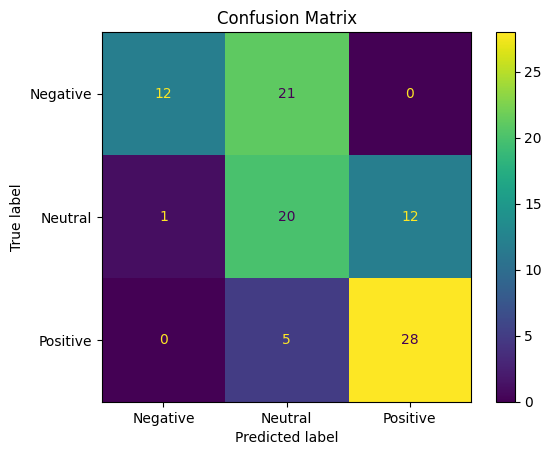

In [16]:
label_map = {2: 'Positive', 1: 'Neutral', 0: 'Negative'}

def predict_sentiments(text, model, tokenizer):
    # Tokenize the text
    encoded_dict = tokenizer([text], return_tensors="pt", padding='longest', truncation=True) 

    # Perform inference
    with torch.no_grad():
        outputs = model(encoded_dict.input_ids, attention_mask=encoded_dict.attention_mask)

    logits = outputs.logits
    predicted_label = torch.argmax(logits, dim=1).item()

    # Map numerical label back to original label
    return label_map[int(predicted_label)]

predict_labels = predict_df['Review'].apply(lambda review: predict_sentiments(review, model, tokenizer)).tolist()

show_results(predict_df['Sentiment'].tolist(), predict_labels)